In [1]:
import badgers
badgers.__version__

'0.0.15'

In [2]:
from badgers.generators.tabular_data.relationship.causal import CausalEdgePerturbationGenerator

g++ not available, if using conda: `conda install gxx`


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import pandas as pd

In [4]:
def generate_linear_data(graph, n_samples=100, rng=None, coefficients=None):
    """Generate data from a linear structural equation model on a DAG.

    Each edge (u -> v) carries a coefficient w. Every node value is
        v = sum_{u in parents(v)} w_{u,v} * u + noise
    with noise ~ N(0, 1).
    """
    if rng is None:
        rng = np.random.default_rng(42)
    if coefficients is None:
        coefficients = {edge: 1.0 for edge in graph.edges()}

    nodes = list(graph.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    X = np.zeros((n_samples, len(nodes)))
    for node in nx.topological_sort(graph):
        idx = node_to_idx[node]
        parents = list(graph.predecessors(node))
        if not parents:
            X[:, idx] = rng.normal(size=n_samples)
        else:
            X[:, idx] = rng.normal(size=n_samples)
            for parent in parents:
                coef = coefficients.get((parent, node), 1.0)
                X[:, idx] += coef * X[:, node_to_idx[parent]]
    return X, {node: i for i, node in enumerate(nodes)}


def draw_graph(graph, title=None):
    """Draw a DAG with node labels."""
    fig, ax = plt.subplots(1, figsize=(6, 2))
    pos = nx.spring_layout(graph, seed=42)
    nx.draw(graph, pos, ax=ax, node_color="lightblue", node_size=800, arrowsize=15)
    nx.draw_networkx_labels(graph, pos, ax=ax)
    if title:
        ax.set_title(title, fontsize=12)
    ax.axis("off")
    return fig


def plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name="X", y_name="Y"):
    """Original | Transformed scatter of two dimensions.

    The transformed panel is coloured by the generator's labels (which rows
    received the defect). Rows with NaN values are drawn as black 'x' markers.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    sns.scatterplot(x=X[:, x_idx], y=X[:, y_idx], color="C0", ax=axes[0])
    sns.scatterplot(x=Xt[:, x_idx], y=Xt[:, y_idx], color="C1", ax=axes[1])
    axes[0].set_title("Original")
    axes[1].set_title("Transformed")
    axes[0].set_xlabel(x_name)
    axes[1].set_xlabel(x_name)
    axes[0].set_ylabel(y_name)
    axes[1].set_ylabel(y_name)
    plt.tight_layout()
    return fig

## 1. Building the causal graph

Unlike the classic Badgers generators, the causal generators take a **causal graph** (a directed acyclic graph, or DAG) as input. The graph plays two roles:

1. **It defines the data.** We generate the data *from* the graph using a linear structural equation model, so the graph genuinely explains how the columns are related.
2. **It drives the defect.** When a node is perturbed, the effect **propagates to its descendants** along the directed edges and nowhere else.

For these tutorials we use a simple **chain** `X → Y → Z`:

- **X** is a root (exogenous) node.
- **Y** depends on X.
- **Z** depends on Y.

We represent the graph with `networkx.DiGraph` and provide an explicit `column_mapping` that tells the generator which column of the data each node lives in.


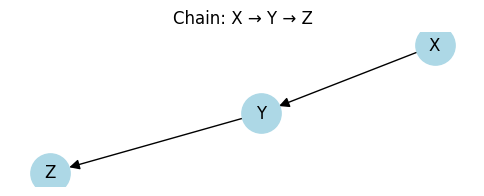

In [5]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

draw_graph(chain, title="Chain: X → Y → Z")
plt.show()


## 2. Generating data from the DAG

We draw 100 samples from the chain. Each node is a weighted sum of its parents plus Gaussian noise; the edge weights set the strength of each causal effect.


In [6]:
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={("X", "Y"): 1, ("Y", "Z"): -1},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")


X shape: (100, 3)
column_mapping: {'X': 0, 'Y': 1, 'Z': 2}


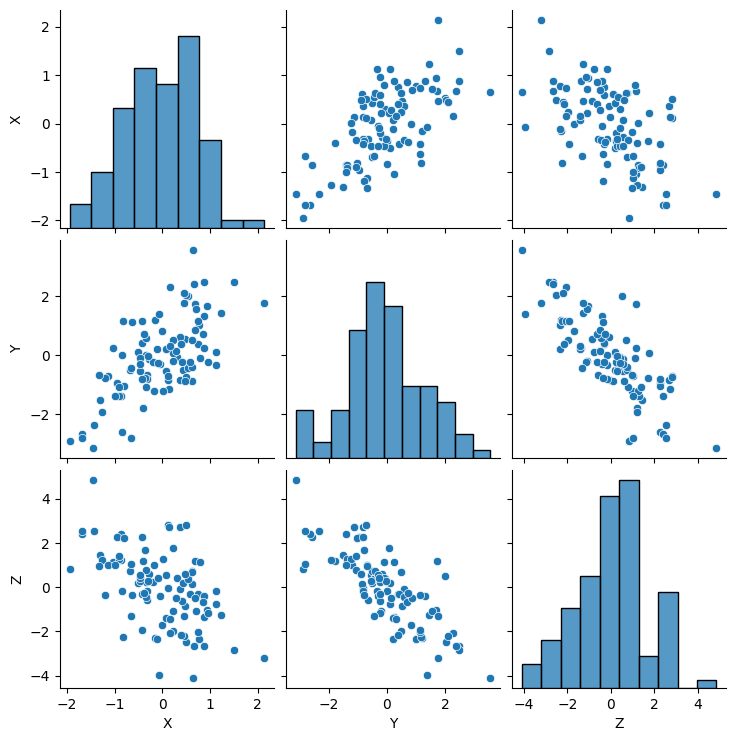

In [7]:
sns.pairplot(pd.DataFrame(X,columns=column_mapping.keys()))

## 3. Fitting the data generation process (DGP)

Causal generators run in **two phases**:

1. **`fit(X, graph, column_mapping)`** — fits a Bayesian data generation process (a `PyMCDGP`, built on PyMC) to the *original* data. It learns, for every node, the linear coefficients from its parents and the residual noise.
2. **`generate(...)`** — perturbs the chosen node(s), then **propagates** the effect to descendants using the fitted structural equations.

Fitting needs the optional `causal` extra (`pip install "badgers[causal]"`). We use a modest number of MCMC samples for speed; raise `n_samples_mcmc` for a more precise fit, or lower it for a faster notebook.


In [8]:
gen = CausalEdgePerturbationGenerator(random_generator=np.random.default_rng(0))
gen.fit(X.copy(), chain, column_mapping, n_samples_mcmc=500)
print("DGP fitted on", X.shape[0], "rows")


Initializing NUTS using jitter+adapt_diag...


C:\Users\siebert\PycharmProjects\badgers\.venv\Lib\site-packages\pytensor\tensor\rewriting\elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(


Sequential sampling (1 chains in 1 job)


NUTS: [mu_X, sigma_X, X_X, sigma_obs_X, beta_Y, sigma_Y, X_Y, sigma_obs_Y, beta_Z, sigma_Z, X_Z, sigma_obs_Z]


Sampling 1 chain for 250 tune and 500 draw iterations (250 + 500 draws total) took 1 seconds.


Only one chain was sampled, this makes it impossible to run some convergence checks


DGP fitted on 100 rows


## 4. Generate a relationship (edge-weight) perturbation

    "The `CausalEdgePerturbationGenerator` changes the **strength of a single edge** and **recomputes the child** with the new coefficient — its structural equation itself changed, and the child's **marginal variance is preserved** by adjusting its residual noise. The child's descendants are then shifted by the propagated **delta** (`beta @ delta_parents` on top of their original values), so their own exogenous noise is preserved. We double the `X → Y` coefficient (`weight_factor=2.0`): the X → Y relationship becomes stronger while Y's overall spread stays the same.\n",

Two constraints matter here:

- `perturbation_nodes` must be the **child** of the perturbed edge — here `["Y"]`.
- The perturbation is only **feasible** while `beta'^2 * var(parent) <= var(child)`. That is why this notebook uses a *weak* `X → Y` edge (coefficient 0.3): with a strong edge, doubling it would push the child's implied variance above its observed variance and the generator would raise `ValueError`.


In [9]:
Xt, yt = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    edge=("X", "Y"),
    weight_factor=-1.0,
)
print(f"output shape: {Xt.shape}")


output shape: (100, 3)


In [10]:
Xt[:5]

array([[ 0.30471708, -0.21670034,  0.55346348],
       [-1.03998411,  1.0289755 ,  0.38286619],
       [ 0.7504512 , -0.21139274,  0.29854759],
       [ 0.94056472, -0.94481055,  1.57389307],
       [-1.95103519,  1.64992811, -3.67441596]])

### The transformed X → Y relationship

In the transformed panel the points hug the (steeper) X → Y line more tightly — the correlation is stronger — while Y's marginal spread is essentially unchanged:


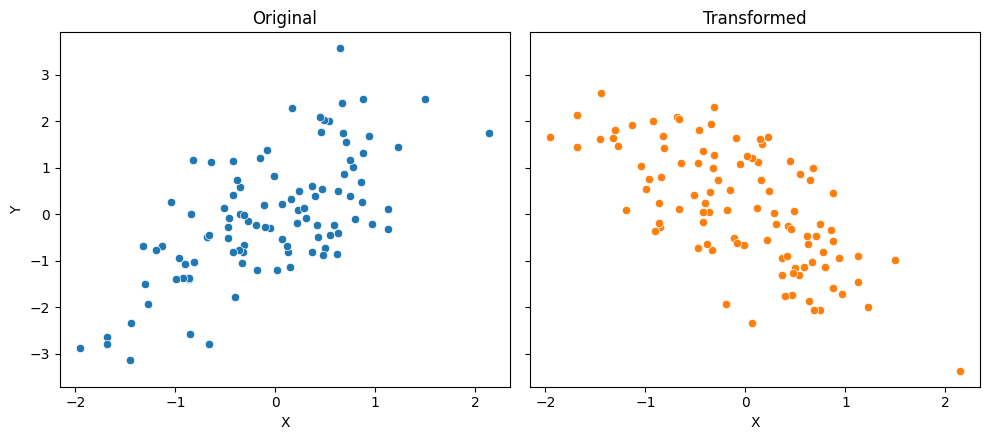

In [11]:
_ = plot_2panel(X, Xt, yt, x_name='X', y_name='Y')

### Propagation to the descendant (Y → Z)

Z moves by exactly `beta_YZ * (Y_new − Y_orig)` on top of its original values — the delta propagated from the recomputed Y — so Z's own residual noise is unchanged.


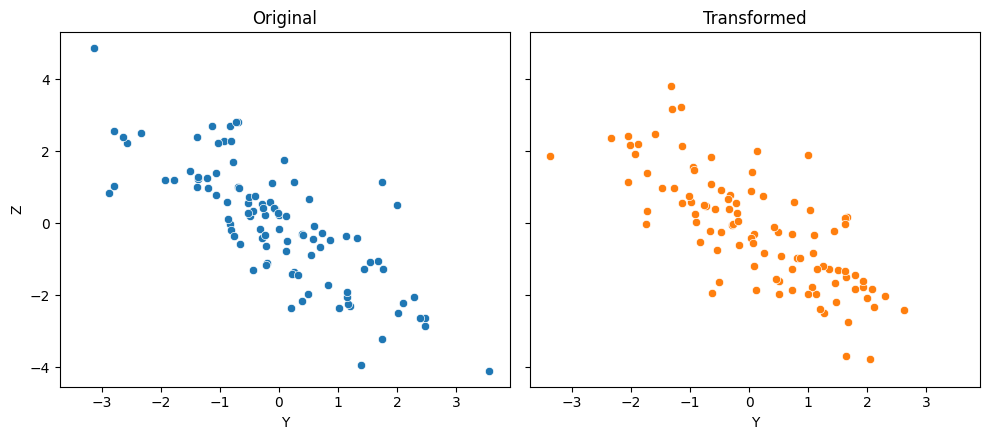

In [12]:
_ = plot_2panel(X, Xt, yt, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

### Infeasible perturbation

Pushing `weight_factor` too far violates the feasibility bound. On this weak edge, a factor of 10 is infeasible:


In [13]:
try:
    gen.generate(X.copy(), y=None,
                 perturbation_nodes=["Y"],
                 edge=("X", "Y"), weight_factor=10.0)
except ValueError as e:
    print(f"ValueError: {e}")


ValueError: Edge perturbation is infeasible: beta'^2 * var(X) > var(Y). Reduce weight_factor.


## Summary

1. Edge perturbation scales one coefficient and preserves the child's marginal variance.
2. `perturbation_nodes` must be the child of the edge.
3. Feasibility requires `beta'^2 * var(parent) <= var(child)` — use weaker edges for larger `weight_factor`.
